In [10]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tf_keras as keras

In [11]:
import tensorflow as tf

train = tf.keras.utils.image_dataset_from_directory(
    "../data/classification/Train",
    image_size=(224, 224),
    batch_size=16,
    shuffle=True
)

val = tf.keras.utils.image_dataset_from_directory(
    "../data/classification/Val",
    image_size=(224, 224),
    batch_size=16,
    shuffle=False
)

test = tf.keras.utils.image_dataset_from_directory(
    "../data/classification/Test",
    image_size=(224, 224),
    batch_size=16,
    shuffle=False
)

Found 4218 files belonging to 4 classes.
Found 787 files belonging to 4 classes.
Found 789 files belonging to 4 classes.


In [12]:
# def preprocess(images, labels):
#     images = tf.cast(images, tf.float32)
#     images = images / 127.5 - 1
#     return images, labels

# train = train.map(preprocess)
# val = val.map(preprocess)
# test = test.map(preprocess)

In [13]:


base_model = keras.applications.InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(299, 299, 3),
    pooling="avg"
)

base_model.trainable = False


In [14]:
model = keras.Sequential([
    keras.layers.Input(shape=(224, 224, 3)),

    # Redimensionner les images
    keras.layers.Resizing(299, 299),

    # Prétraiter les pixels pour InceptionV3
    keras.layers.Lambda(
        keras.applications.inception_v3.preprocess_input
    ),

    # Extraire les caractéristiques
    base_model,

    # Réduire le surapprentissage
    keras.layers.Dropout(0.4),

    # Classifier les 4 catégories
    keras.layers.Dense(4, activation="softmax")
])

In [15]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resizing_1 (Resizing)       (None, 299, 299, 3)       0         
                                                                 
 lambda_1 (Lambda)           (None, 299, 299, 3)       0         
                                                                 
 inception_v3 (Functional)   (None, 2048)              21802784  
                                                                 
 dropout_1 (Dropout)         (None, 2048)              0         
                                                                 
 dense_1 (Dense)             (None, 4)                 8196      
                                                                 
Total params: 21810980 (83.20 MB)
Trainable params: 8196 (32.02 KB)
Non-trainable params: 21802784 (83.17 MB)
_________________________________________________________________


In [16]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_inceptionv3.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

In [17]:
history = model.fit(
    train,
    validation_data=val,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
264/264 [==============================] - 28s 97ms/step - loss: 0.6473 - accuracy: 0.7444 - val_loss: 0.4915 - val_accuracy: 0.8056
Epoch 2/15
264/264 [==============================] - 25s 94ms/step - loss: 0.4052 - accuracy: 0.8561 - val_loss: 0.4175 - val_accuracy: 0.8424
Epoch 3/15
264/264 [==============================] - 25s 95ms/step - loss: 0.3653 - accuracy: 0.8661 - val_loss: 0.3731 - val_accuracy: 0.8450
Epoch 4/15
264/264 [==============================] - 25s 94ms/step - loss: 0.3205 - accuracy: 0.8789 - val_loss: 0.3491 - val_accuracy: 0.8640
Epoch 5/15
264/264 [==============================] - 24s 91ms/step - loss: 0.3073 - accuracy: 0.8822 - val_loss: 0.3628 - val_accuracy: 0.8551
Epoch 6/15
264/264 [==============================] - 25s 95ms/step - loss: 0.2869 - accuracy: 0.8931 - val_loss: 0.3313 - val_accuracy: 0.8691
Epoch 7/15
264/264 [==============================] - 24s 92ms/step - loss: 0.2739 - accuracy: 0.8973 - val_loss: 0.3363 - val_accuracy:

50/50 [==============================] - 4s 75ms/step
              precision    recall  f1-score   support

      Glioma     0.9371    0.8454    0.8889       194
  Meningioma     0.8760    0.9163    0.8957       239
    No Tumor     0.9664    0.9426    0.9544       122
   Pituitary     0.9102    0.9530    0.9311       234

    accuracy                         0.9138       789
   macro avg     0.9224    0.9143    0.9175       789
weighted avg     0.9152    0.9138    0.9136       789



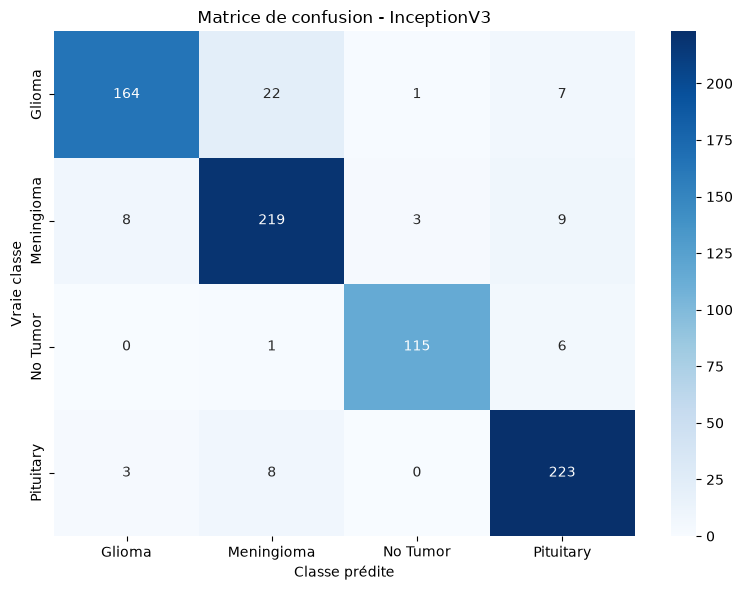

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Les vraies classes
y_true = np.concatenate([
    labels.numpy() for images, labels in test
])

# Les prédictions du modèle
y_prob = model.predict(test)
y_pred = np.argmax(y_prob, axis=1)

# Les noms des classes
class_names = test.class_names

# Rapport détaillé
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Classe prédite")
plt.ylabel("Vraie classe")
plt.title("Matrice de confusion - InceptionV3")
plt.tight_layout()
plt.show()

In [20]:

# Évaluer le modèle sur le jeu de test
test_loss, test_accuracy = model.evaluate(test)

print(f"Test loss : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.2%}")


49/50 [============================>.] - ETA: 0s - loss: 0.2535 - accuracy: 0.9133

W0000 00:00:1793007776.077080   39273 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.00GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


50/50 [==============================] - 5s 102ms/step - loss: 0.2520 - accuracy: 0.9138
Test loss : 0.2520
Test accuracy : 91.38%


In [26]:
model.save("../model/classification.keras")